In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

# Часть 1. EDA и Preprocessing.

1. Скачайте данные по клиентам немецкого банка: https://www.kaggle.com/uciml/german-credit;
2. Проведите EDA, чтобы познакомиться с признаками;
3. Преобразуйте все признаки в числовые подходящими методами;
4. Приведите все данные к одному масштабу (а заодно поясните, почему это необходимая операция при кластеризации).

In [100]:
df_raw_path = "data/raw/german_credit_data.csv"
df_raw = pd.read_csv(df_raw_path, sep=",", encoding="utf-8")
df_raw.head(3)

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education


## EDA

### Знакомство с данными

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
dtypes: int64(5), str(5)
memory usage: 78.3 KB


In [ ]:
df_raw.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [6]:
df_raw.describe(include=["str", "object"])

,Sex,Housing,Saving accounts,Checking account,Purpose
count,1000,1000,817,606,1000
unique,2,3,4,3,8
top,male,own,little,little,car
freq,690,713,603,274,337


In [11]:
df_raw.isna().sum()

Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

In [13]:
df_raw.duplicated().sum()

np.int64(0)

### Распределение признаков

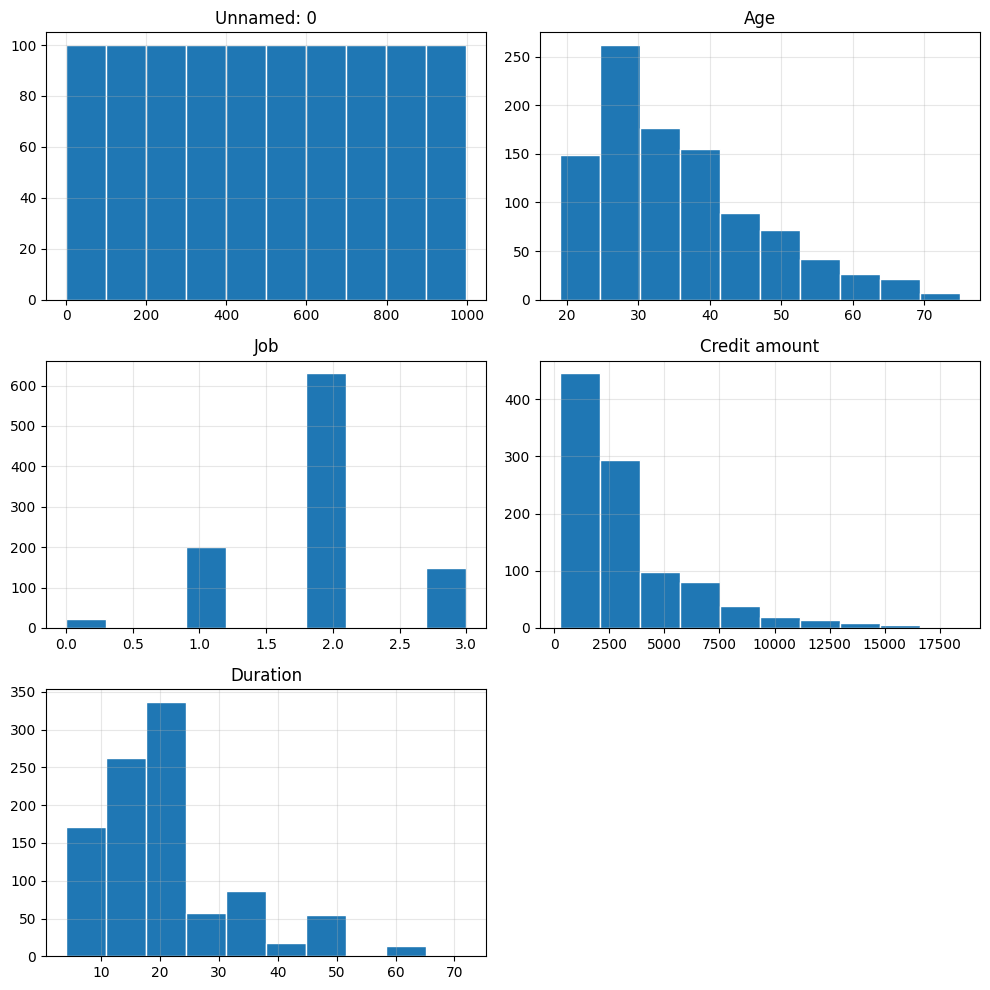

In [102]:
df_raw.hist(
    figsize=(10,10),
    bins=10,
    edgecolor="white"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

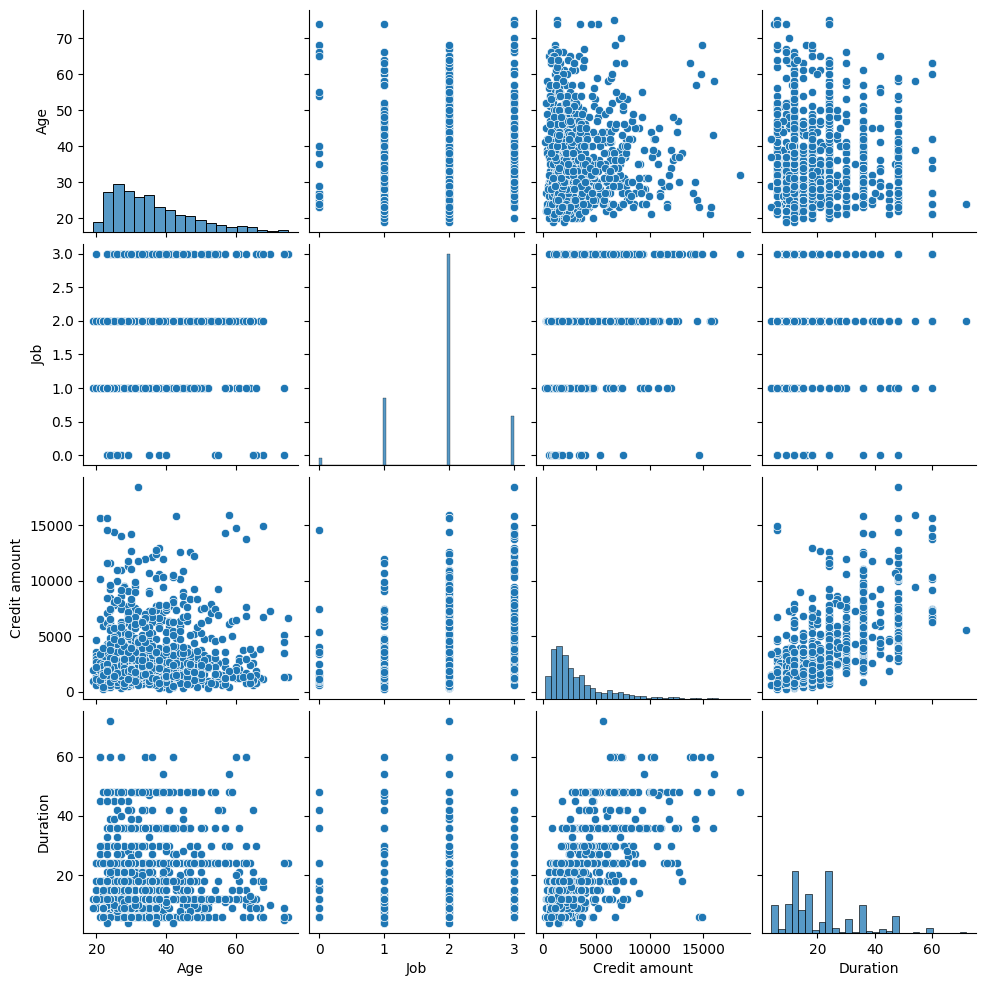

In [40]:
sns.pairplot(data=df_raw.drop(columns=["Unnamed: 0"]));

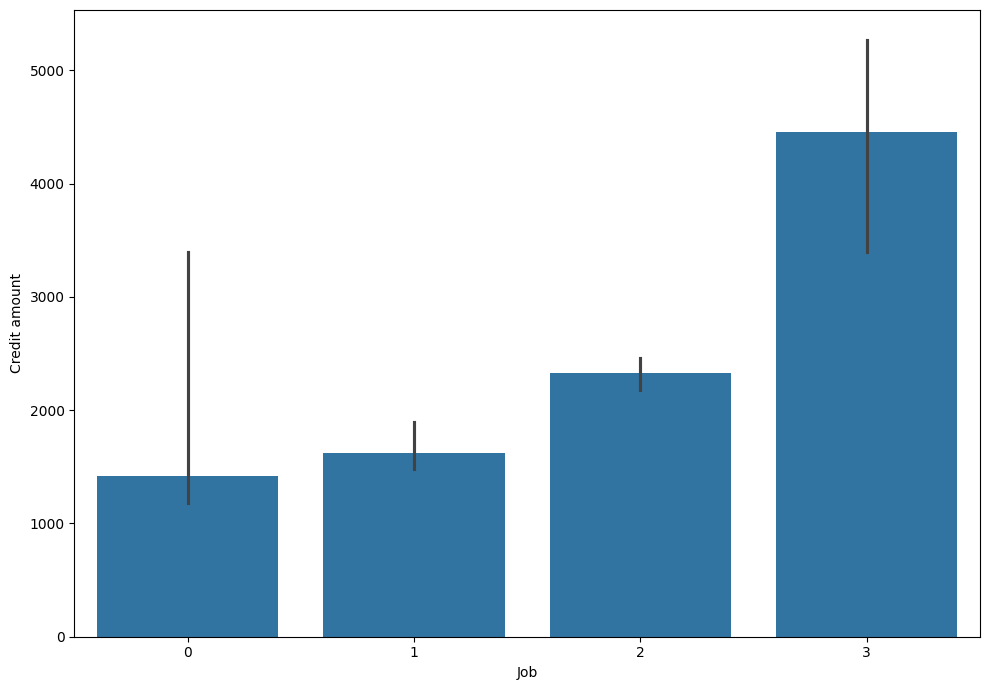

In [ ]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=df_raw,
    x="Job",
    y="Credit amount",
    estimator="median"
)

plt.tight_layout()
plt.show()

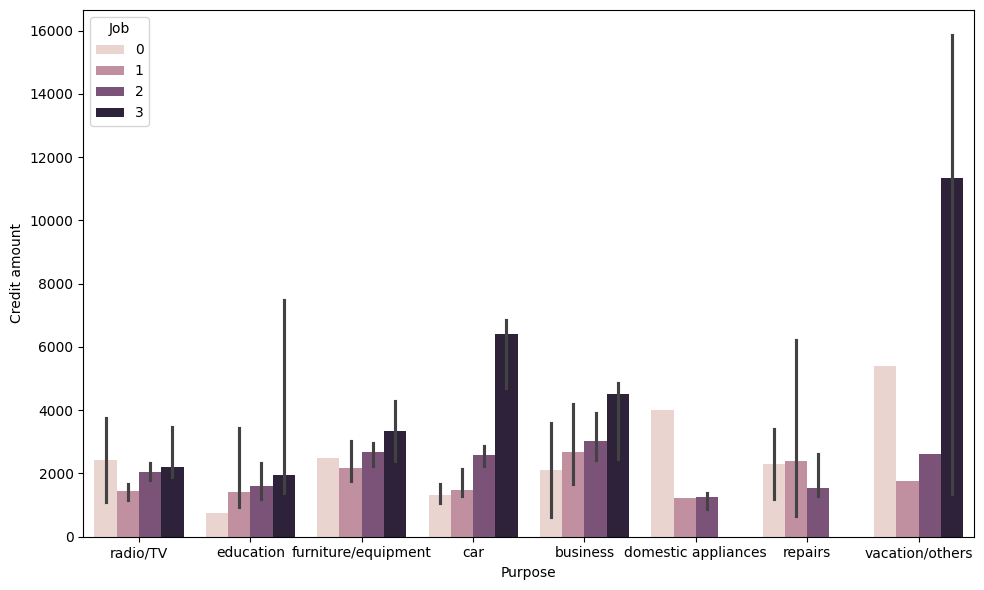

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_raw,
    x="Purpose",
    y="Credit amount",
    hue="Job",
    estimator="median"
)

plt.tight_layout()
plt.show()

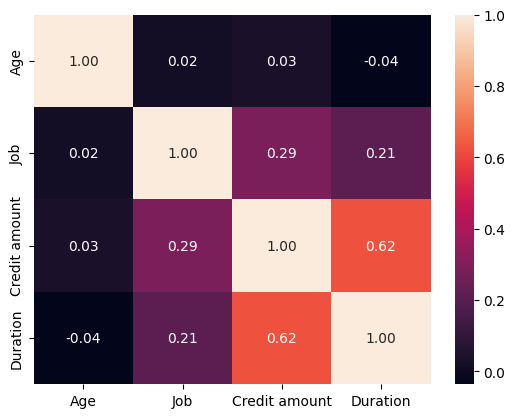

In [85]:
sns.heatmap(
    data=df_raw.drop(columns=["Unnamed: 0"]).corr(numeric_only=True),
    annot=True,
    fmt=".2f"
);

## Preprocessing

**отбор признаков**

In [160]:
df_interim = df_raw.drop(columns=["Unnamed: 0"])
df_interim.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


**обработка пропусков**

In [161]:
df_interim.describe(include=["str", "object"])

,Sex,Housing,Saving accounts,Checking account,Purpose
count,1000,1000,817,606,1000
unique,2,3,4,3,8
top,male,own,little,little,car
freq,690,713,603,274,337


In [162]:
df_interim["Saving accounts"].value_counts()

Saving accounts
little        603
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64

In [163]:
df_interim["Checking account"].value_counts()

Checking account
little      274
moderate    269
rich         63
Name: count, dtype: int64

In [164]:
df_interim["Saving accounts"] = df_interim["Saving accounts"].fillna("no account")
df_interim["Checking account"] = df_interim["Checking account"].fillna("no account")
df_interim.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,no account,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,no account,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


In [165]:
df_interim.describe(include=["str", "object"])

,Sex,Housing,Saving accounts,Checking account,Purpose
count,1000,1000,1000,1000,1000
unique,2,3,5,4,8
top,male,own,little,no account,car
freq,690,713,603,394,337


In [18]:
df_interim_path = "data/interim/df_filled_empty.csv"

In [167]:
df_interim.to_csv(df_interim_path, sep=",", index=False)

### Преобразование категориальных признаков

In [19]:
df_prep = pd.read_csv(df_interim_path, sep=",", encoding="utf-8")
df_prep.head(3)

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,no account,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,no account,2096,12,education


In [ ]:
str_cols = df_prep.select_dtypes(include=["str", "object"]).columns.tolist()

with pd.option_context("display.max_colwidth", None):
    print(df_prep[str_cols].apply(pd.unique))

Sex                                                                                                           [male, female]
Housing                                                                                                    [own, free, rent]
Saving accounts                                                             [no account, little, quite rich, rich, moderate]
Checking account                                                                        [little, moderate, no account, rich]
Purpose             [radio/TV, education, furniture/equipment, car, business, domestic appliances, repairs, vacation/others]
dtype: object


**кодирование бинарных признаков**

In [21]:
df_prep["Sex"]=df_prep["Sex"].map({"male":1, "female":0})
df_prep.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,1,2,own,no account,little,1169,6,radio/TV
1,22,0,2,own,little,moderate,5951,48,radio/TV
2,49,1,1,own,little,no account,2096,12,education
3,45,1,2,free,little,little,7882,42,furniture/equipment
4,53,1,2,free,little,little,4870,24,car


**попытка в пайплайны из 13 Практическое занятие - Построение end-to-end пайплайнов и сериализация моделей**

In [22]:
saving_order = ["no account", "little", "moderate", "quite rich", "rich"]
checking_order = ["no account", "little", "moderate", "rich"]

cols_to_oe = ["Saving accounts", "Checking account"]
cols_to_ohe = ["Housing", "Purpose"]

preprocessor = ColumnTransformer(
    transformers=[
        # кодирование порядковых признаков
        ("oe",
         OrdinalEncoder(categories=[saving_order, checking_order], dtype=int), 
         cols_to_oe),
        # кодирование номинальных признаков
        ("ohe",
         OneHotEncoder(drop=None, sparse_output=False, dtype=int), 
         cols_to_ohe)
    ],
    # остальные столбцы ез изменений
    remainder="passthrough",
    verbose_feature_names_out=False #изабвляет от префиксов oe__ ohe__ remainder__в  названиях фичей
)

preprocessor.set_output(transform="pandas")

df_eсcoded = preprocessor.fit_transform(df_prep)
df_eсcoded.head(3) # type: ignore

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
0,0,1,0,1,0,0,0,0,0,0,1,0,0,67,1,2,1169,6
1,1,2,0,1,0,0,0,0,0,0,1,0,0,22,0,2,5951,48
2,1,0,0,1,0,0,0,0,1,0,0,0,0,49,1,1,2096,12


In [202]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('oe', ...), ('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transforme

*для себя:*

1. oe однострочнй аналог фиттрансформа типа 

```py
oe = OrdinalEncoder(categories=[saving_order, checking_order], dtype=int)
df_prep[cols_to_oe] = oe.fit_transform(df_prep[cols_to_oe])
```

2. ohe однострочнй аналог фиттрансформа (или гетдамис, уточнить разницу при сдаче дз)

```py
encoded_res = ohe.fit_transform(df_prep[cols_to_ohe])

eccoded_df = pd.DataFrame(
    encoded_res, 
    columns=ohe.get_feature_names_out(cols_to_ohe),
    index=df_prep.index
)

df_prep = df_prep.drop(columns=cols_to_ohe)
df_prep = pd.concat([df_prep, eccoded_df], axis=1)
```

In [134]:
df_encoded_path = "data/interim/df_encoded_pipeline.csv"

In [ ]:
df_eсcoded.to_csv(df_encoded_path, sep=",", index=False) # type: ignore

### Масштабирвоание

In [14]:
# это тоже можно было впихнуть в пайплайн
scaler = StandardScaler()

scaler.set_output(transform="pandas")

# X_scaled = scaler.fit_transform(df_eсcoded)
# df_scaled =  pd.DataFrame(X_scaled) # можно добавить columns=df_eсcoded.columns и не пистаь set_output
# выше - двустрочник из лекции как альтернатива моему варианту
df_scaled = pd.DataFrame(scaler.fit_transform(df_eсcoded))
df_scaled.head(3)

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
0,-1.231393,-0.001045,-0.34796,0.634448,-0.466933,-0.327749,-0.712949,-0.110208,-0.250398,-0.470108,1.603567,-0.149983,-0.110208,2.766456,0.670280,0.146949,-0.745131,-1.236478
1,-0.196609,1.044372,-0.34796,0.634448,-0.466933,-0.327749,-0.712949,-0.110208,-0.250398,-0.470108,1.603567,-0.149983,-0.110208,-1.191404,-1.491914,0.146949,0.949817,2.248194
2,-0.196609,-1.046463,-0.34796,0.634448,-0.466933,-0.327749,-0.712949,-0.110208,3.993639,-0.470108,-0.623610,-0.149983,-0.110208,1.183312,0.670280,-1.383771,-0.416562,-0.738668


**(а заодно поясните, почему это необходимая операция при кластеризации)**

Суть кластеризации k-means, hierarhical и DBSCAN - объединенеие объектов в группы/кластеры по вычисленному между ними расстоянию (по умолчанию - Евклидово, если не ошибаюсь). Разный числовой масштаб признаков искуственно искажает расстояния между объектами: фичи с большими абсолютными значениями (напр. credit amount=18424) будут при расчете расстояний как бы доминировать и перевешивать математически фичи с маленькими значенимяи (напр. бинарные столбцы или Age от 19 до 75). Алгоритм будет группировать объекты преимущественно по признакам с большими значениями, игрорируя остальные признаки.

Масшатбирование уравнивает значения фичей, давая алгоритму возможность оценить реальную схожесть объектов между собой по всем признакам и сгруппировать их в кластеры по этой схожести.

Наглядный пример изменения масштабов - боксплоты до и после применения StandardScaler:

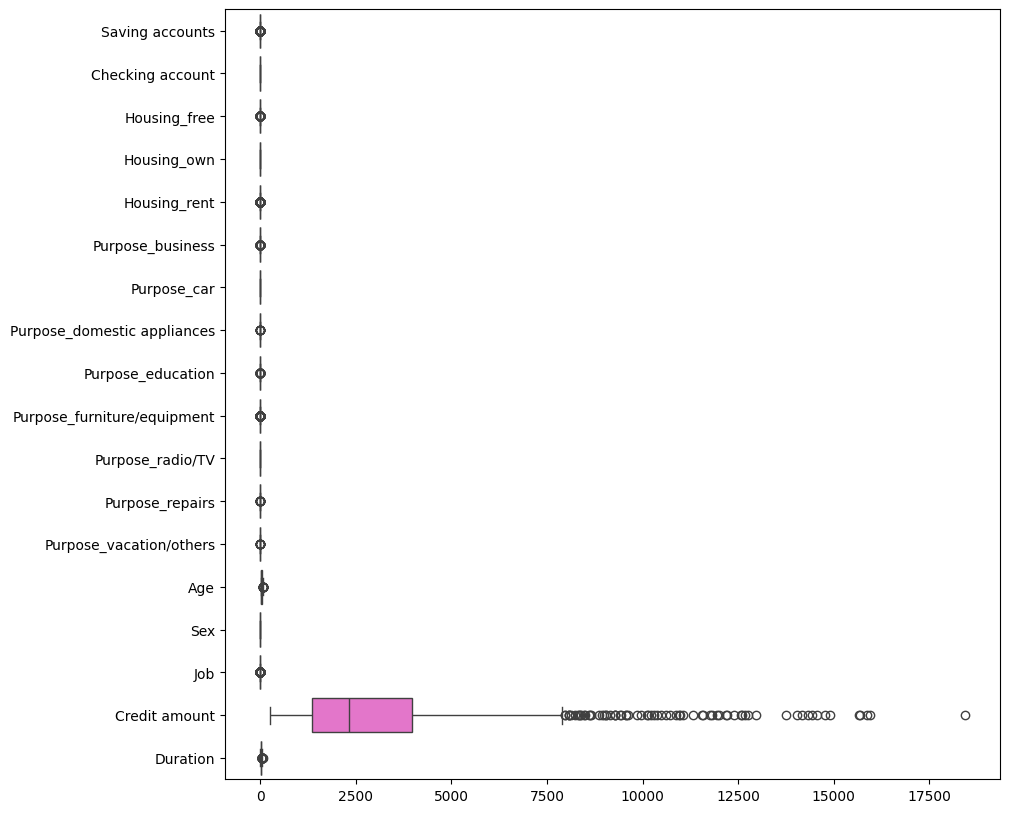

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=df_eсcoded, orient="h"); # type: ignore

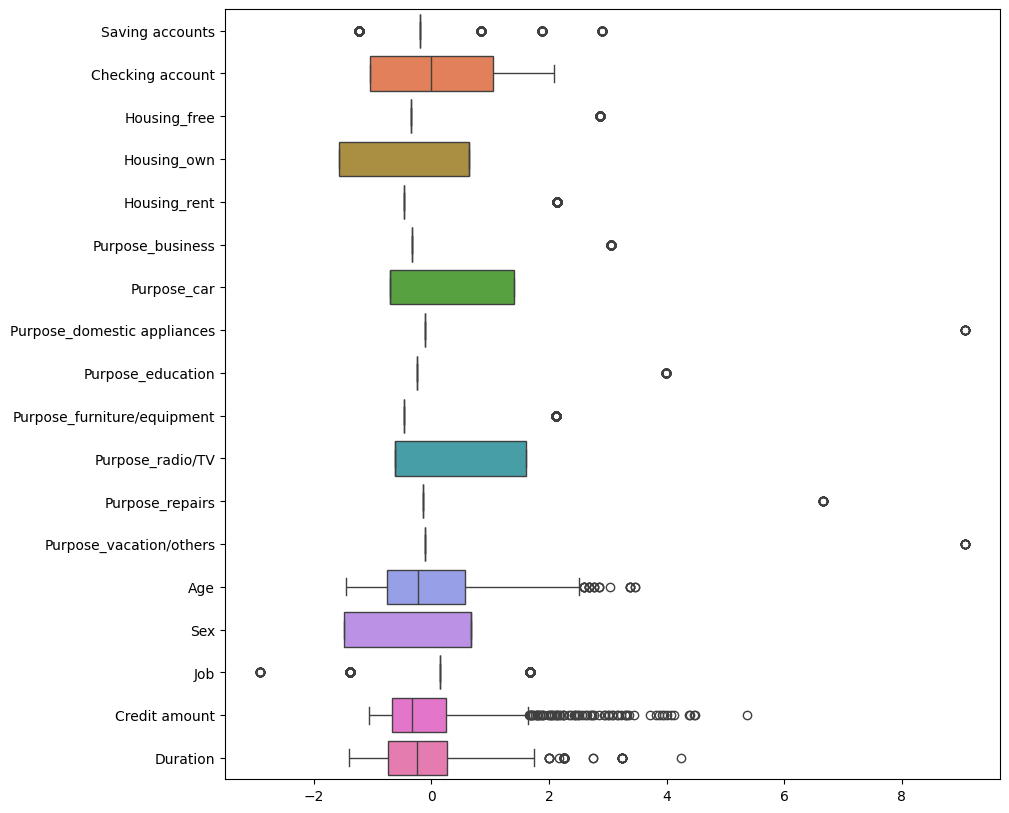

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=df_scaled, orient="h");

In [15]:
df_scaled_path = "data/interim/df_scaled.csv"

In [17]:
df_scaled.to_csv(df_scaled_path, sep=",", index=False)

# Часть 2. Моделирование.

1. Постройте три варианта кластеризации: k-means, hierarhical и DBSCAN, подберите оптимальное количество кластеров для каждого метода при помощи Elbow method и Silhouette plot;
2. Также воспользуйтесь различными вариантами сжатия признакового пространства (PCA, UMAP, tSNE) и визуализируйте результаты кластеризации на двумерной плоскости.

In [137]:
df_eсcoded = pd.read_csv(df_encoded_path, sep=",", encoding="utf-8")
df_eсcoded.head(3)

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
0,0,1,0,1,0,0,0,0,0,0,1,0,0,67,1,2,1169,6
1,1,2,0,1,0,0,0,0,0,0,1,0,0,22,0,2,5951,48
2,1,0,0,1,0,0,0,0,1,0,0,0,0,49,1,1,2096,12


In [28]:
df_scaled = pd.read_csv(df_scaled_path, sep=",", encoding="utf-8")
df_scaled.head(3)

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
0,-1.231393,-0.001045,-0.34796,0.634448,-0.466933,-0.327749,-0.712949,-0.110208,-0.250398,-0.470108,1.603567,-0.149983,-0.110208,2.766456,0.670280,0.146949,-0.745131,-1.236478
1,-0.196609,1.044372,-0.34796,0.634448,-0.466933,-0.327749,-0.712949,-0.110208,-0.250398,-0.470108,1.603567,-0.149983,-0.110208,-1.191404,-1.491914,0.146949,0.949817,2.248194
2,-0.196609,-1.046463,-0.34796,0.634448,-0.466933,-0.327749,-0.712949,-0.110208,3.993639,-0.470108,-0.623610,-0.149983,-0.110208,1.183312,0.670280,-1.383771,-0.416562,-0.738668


In [ ]:
X_pca = PCA(n_components=2, random_state=123).fit_transform(df_scaled)
X_umap = UMAP(n_components=2, random_state=123).fit_transform(df_scaled)
X_tsne = TSNE(n_components=2, random_state=123).fit_transform(df_scaled)

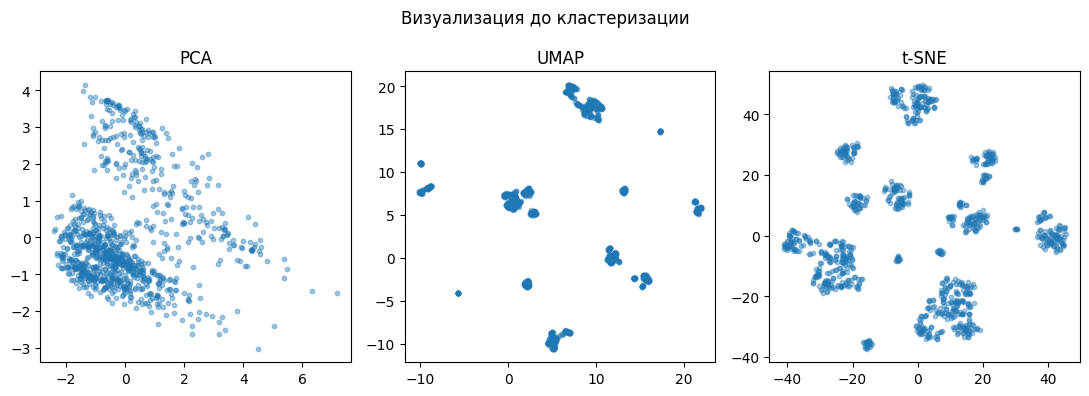

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

methods = [
    ("PCA", X_pca),
    ("UMAP", X_umap), 
    ("t-SNE", X_tsne)
]

for ax, (method, coords) in zip(axes, methods):
  ax.scatter(
    coords[:, 0],
    coords[:, 1],
    s=10,
    alpha=0.4
  )

  ax.set_title(f"{method}")

fig.suptitle("Визуализация до кластеризации")
plt.tight_layout()
plt.show()

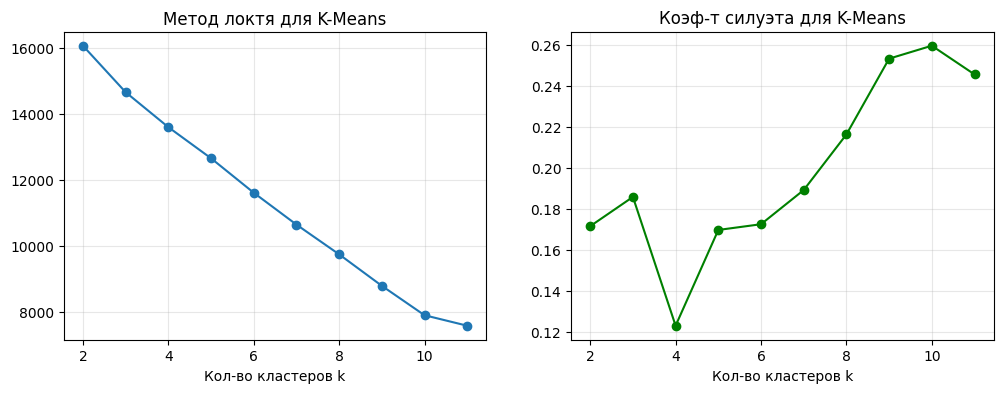

In [ ]:
inertias = []
silhouettes_km = []
rng = range(2, 12)

for k in rng:
  km = KMeans(n_clusters=k, random_state=123, n_init=10)
  labels_km = km.fit_predict(df_scaled)
  inertias.append(km.inertia_)
  silhouettes_km.append(silhouette_score(df_scaled, labels_km))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(rng, inertias, marker="o")
ax1.set_title("Метод локтя для K-Means")
ax1.set_xlabel("Кол-во кластеров k")
ax1.grid(True, alpha=0.3)

ax2.plot(rng, silhouettes_km, marker="o", color="green")
ax2.set_title("Коэф-т силуэта для K-Means")
ax2.set_xlabel("Кол-во кластеров k")
ax2.grid(True, alpha=0.3)

plt.show()

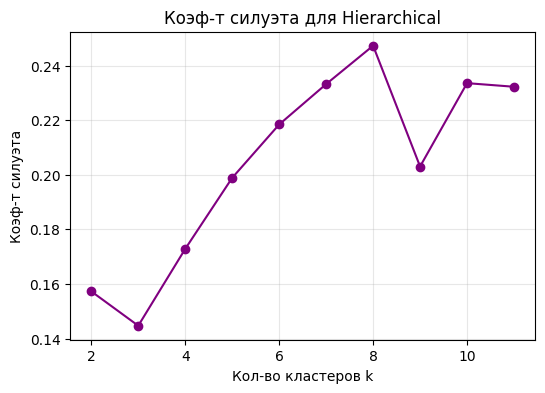

In [111]:
silhouettes_hc = []

for k in rng:
    hc = AgglomerativeClustering(n_clusters=k)
    labels_hc = hc.fit_predict(df_scaled)
    silhouettes_hc.append(silhouette_score(df_scaled, labels_hc))

plt.figure(figsize=(6, 4))
plt.plot(
    rng,
    silhouettes_hc,
    marker="o",
    color="purple"
)

plt.grid(True)

plt.title("Коэф-т силуэта для Hierarchical")
plt.xlabel("Кол-во кластеров k")
plt.ylabel("Коэф-т силуэта")

plt.grid(True, alpha=0.3)
plt.show()

eps=0.5: найдено кластеров = 5, силуэт = -0.256
eps=1.0: найдено кластеров = 17, силуэт = -0.296
eps=1.5: найдено кластеров = 19, силуэт = -0.077
eps=2.0: найдено кластеров = 18, силуэт = 0.083
eps=2.5: найдено кластеров = 12, силуэт = 0.224
eps=3.0: найдено кластеров = 18, силуэт = 0.255
eps=3.5: найдено кластеров = 9, силуэт = 0.204


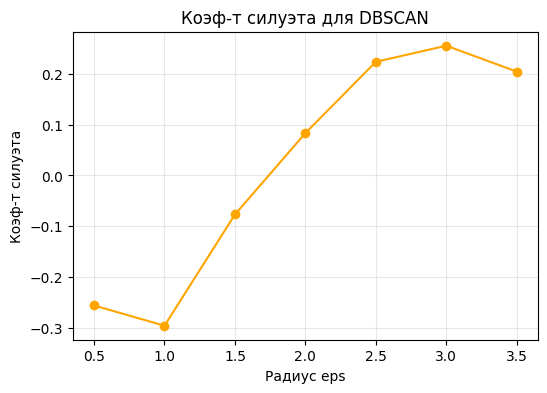

In [116]:
eps_values = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5]
silhouettes_db = []
valid_eps = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5)
    labels_db = db.fit_predict(df_scaled)
    
    # силцэт можно посчитать, елси если алгоритм нашел ХОТЯБЫ 2 кластера
    n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    if n_clusters >= 2:
        score = silhouette_score(df_scaled, labels_db)
        silhouettes_db.append(score)
        valid_eps.append(eps)
        print(f"eps={eps}: найдено кластеров = {n_clusters}, силуэт = {score:.3f}")
    else:
        print(f"eps={eps}: найдено кластеров = {n_clusters}, нелостаочно для расчета силуэта")

plt.figure(figsize=(6, 4))
plt.plot(
    valid_eps,
    silhouettes_db,
    marker="o",
    color="orange"
)

plt.title("Коэф-т силуэта для DBSCAN")
plt.xlabel("Радиус eps")
plt.ylabel("Коэф-т силуэта")

plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# слишком большой радиус может приветси к тому, #что ДБСКАН склеит почти все объекты в 1 радиус
# Т.о. балл силуэта будет искусственно завышен
for eps in [2.0, 2.5, 3.0, 3.5]:
  labels = DBSCAN(eps=eps, min_samples=5).fit_predict(df_scaled)
  print(f"\n--- eps = {eps} ---")
  print(pd.Series(labels).value_counts())


--- eps = 2.0 ---
-1     257
 0     154
 3     152
 8      81
 5      62
 6      54
 10     41
 2      33
 11     32
 9      26
 7      23
 4      21
 13     17
 1      15
 16      9
 15      8
 14      5
 12      5
 17      5
Name: count, dtype: int64

--- eps = 2.5 ---
 0     224
 4     211
-1     139
 3     119
 6      68
 5      59
 7      46
 2      44
 8      32
 1      30
 9      11
 10     10
 11      7
Name: count, dtype: int64

--- eps = 3.0 ---
 0     225
 5     217
 3     122
 7      75
 4      62
-1      58
 2      50
 11     48
 8      36
 1      34
 10     15
 13     12
 6      11
 12      9
 9       7
 14      7
 15      5
 17      4
 16      3
Name: count, dtype: int64

--- eps = 3.5 ---
 0    715
 3     92
 2     80
 1     43
-1     18
 6     17
 4     15
 5      9
 7      6
 8      5
Name: count, dtype: int64


**ИТОГО**
1. K-Means. оптимаьное кол-во коэфициентов = 10 (на графике локтя излом на 10, на графике сиуэта достигает максимума также на 10ти)
2. Hierarchical. оптимаьное кол-во коэфициентов = 8 (на графике сиуэта достигаем максимума на 8)
3. DBSCAN. оптимальный радиус = 3.0 (максимум в точке 3)

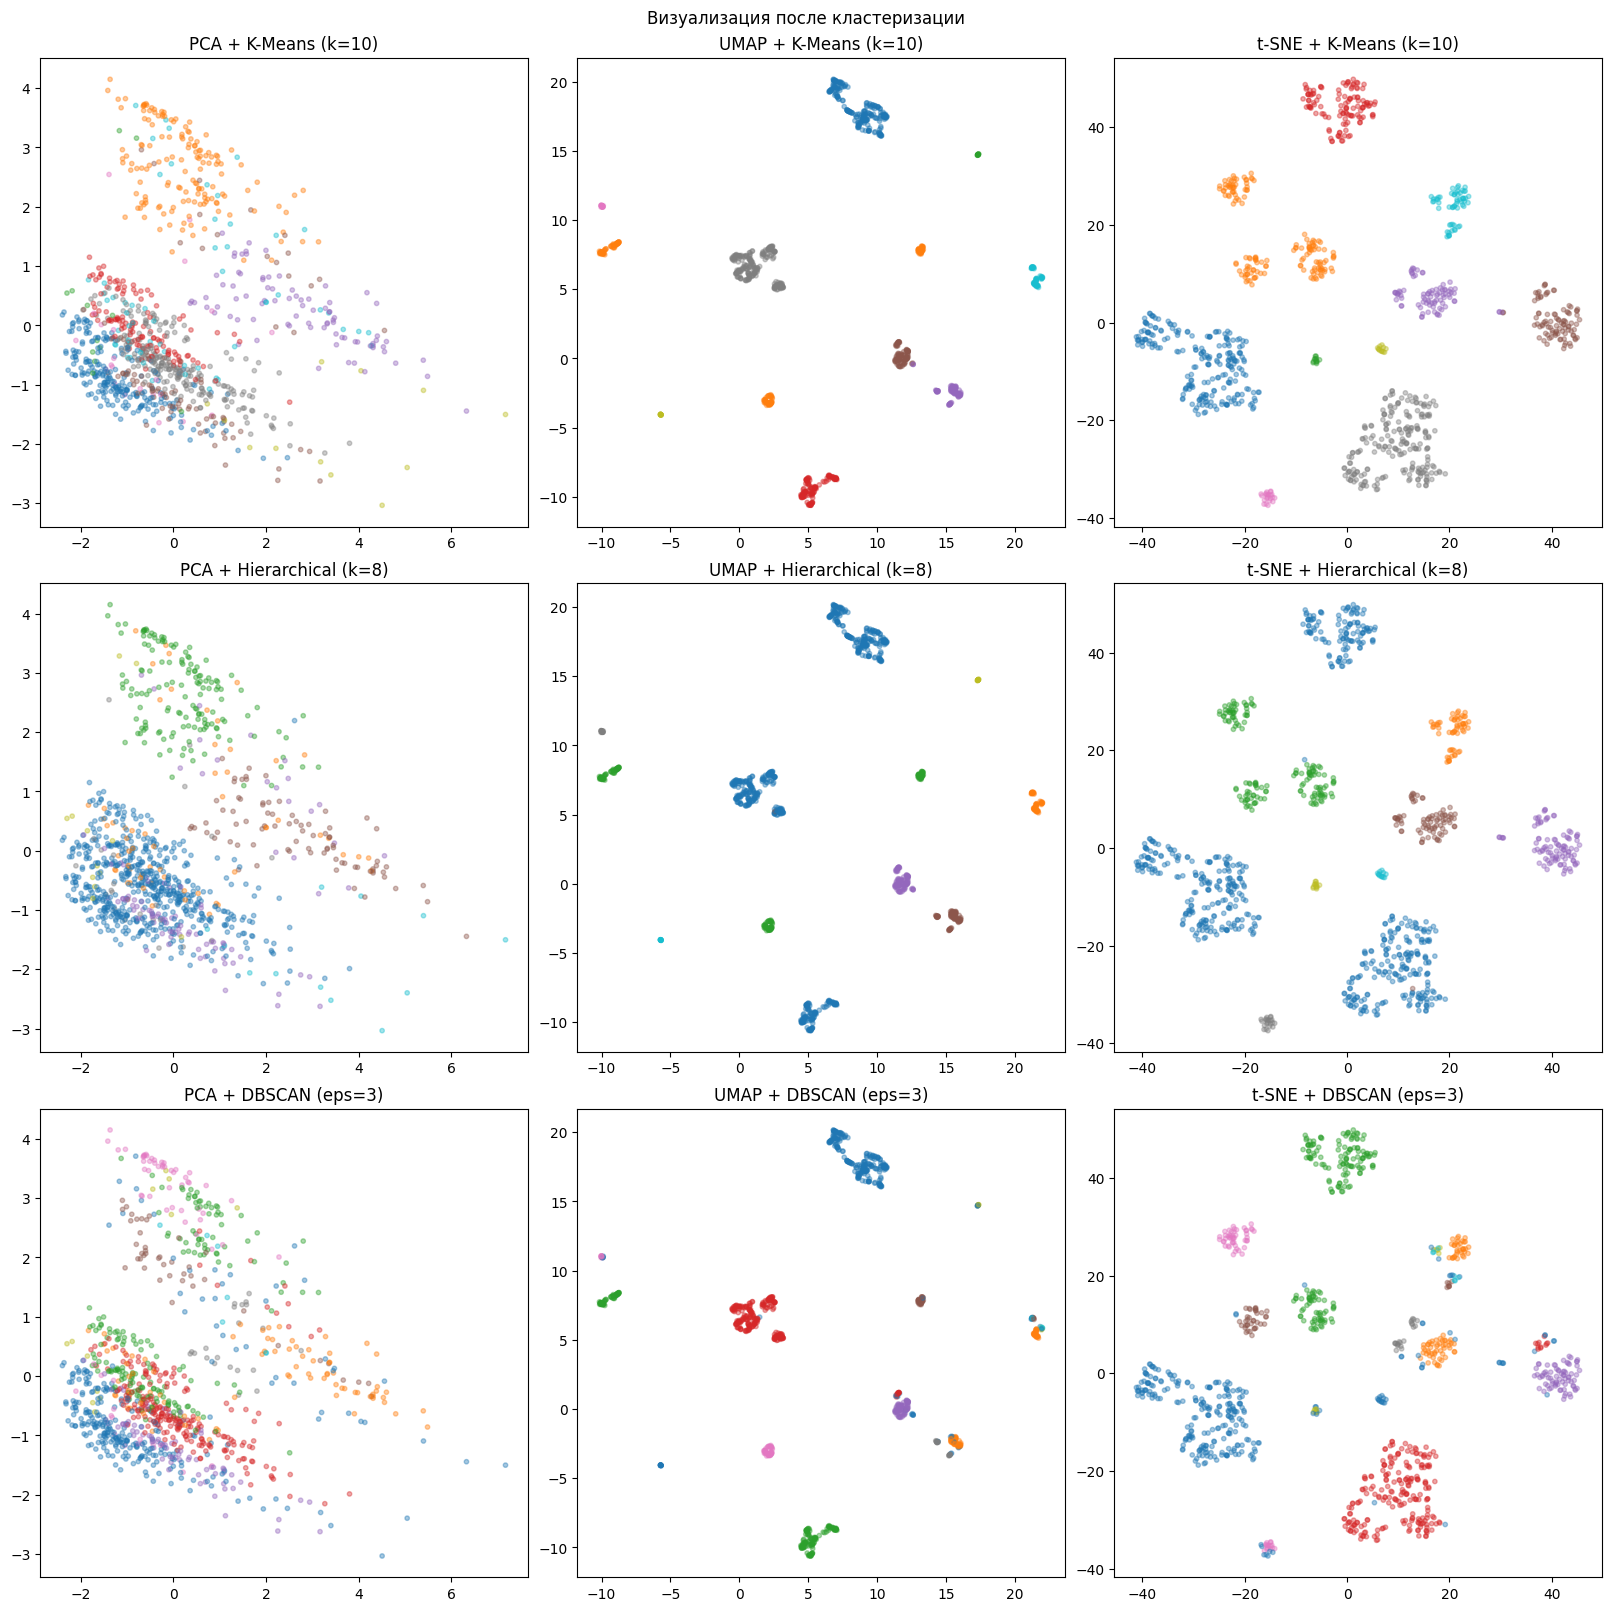

In [ ]:
# финальные метки кластеров с лучшими параметрами
fin_labels_km = KMeans(n_clusters=10, random_state=123, n_init=10).fit_predict(df_scaled)
fin_labels_hc = AgglomerativeClustering(n_clusters=8).fit_predict(df_scaled)
fin_labels_db = DBSCAN(eps=3, min_samples=5).fit_predict(df_scaled)

fig, axes = plt.subplots(3, 3, figsize=(16, 16), layout="constrained") # layout="constrained" - режим автоматически учитывает suptitle без наложений, тогда тайт_лейаут вызывать не надо

cluster_results = [
    ("K-Means (k=10)", fin_labels_km),
    ("Hierarchical (k=8)", fin_labels_hc),
    ("DBSCAN (eps=3)", fin_labels_db)
]

for row, (algorythm, labels) in enumerate(cluster_results):
    for col, (method, coords) in enumerate(methods):
        ax = axes[row, col]
        ax.scatter(
            coords[:, 0],
            coords[:, 1],
            c=labels,
            cmap="tab10",
            s=10,
            alpha=0.4
        )

        ax.set_title(f"{method} + {algorythm}")

fig.suptitle("Визуализация после кластеризации")

# plt.tight_layout()
plt.show()

# Часть 3. Интерпретация.

1. Теперь ваша задача - попытаться проинтерпретировать получившиеся кластеры, начните с простого расчета средних значений признаков для каждого из кластеров, есть ли интересные закономерности?
3. Теперь постройте boxplot-ы для каждого признака, сгруппировав значения по кластерам, по каким признакам заметно наибольшее отличие кластеров друг от друга? Можно ли их интерпретировать?

In [ ]:
df_result = df_eсcoded.copy()
df_result["cluster_km"] = labels_km
df_result["cluster_hc"] = labels_hc
df_result["cluster_db"] = labels_db

### Закономерности

In [145]:
cluster_means_km = df_result.drop(columns=["cluster_hc", "cluster_db"]).groupby("cluster_km").mean().round(2)
display(cluster_means_km)

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
cluster_km,,,,,,,,,,,,,,,,,,
0,0.95,1.13,1.00,0.00,0.00,0.04,0.65,0.0,0.0,0.13,0.18,0.0,0.0,43.99,0.85,2.25,4990.40,26.62
1,1.17,0.97,0.00,1.00,0.00,0.00,0.00,0.0,0.0,0.00,1.00,0.0,0.0,35.11,0.70,1.84,2540.49,20.22
2,1.26,0.97,0.00,0.00,1.00,0.00,0.42,0.0,0.0,0.32,0.26,0.0,0.0,29.84,0.45,1.86,2914.40,17.96
3,1.24,1.05,0.00,1.00,0.00,0.00,0.00,0.0,0.0,1.00,0.00,0.0,0.0,33.67,0.69,1.92,3107.46,19.93
4,1.32,1.11,0.02,0.81,0.17,1.00,0.00,0.0,0.0,0.00,0.00,0.0,0.0,35.12,0.81,1.88,4110.40,26.62
5,1.41,1.05,0.14,0.77,0.09,0.00,0.00,0.0,0.0,0.00,0.00,1.0,0.0,38.55,0.77,1.50,2728.09,19.09
6,1.21,0.90,0.00,1.00,0.00,0.00,1.00,0.0,0.0,0.00,0.00,0.0,0.0,36.66,0.76,1.90,3329.95,19.61
7,1.03,1.00,0.25,0.58,0.17,0.00,0.00,0.0,1.0,0.00,0.00,0.0,0.0,38.29,0.59,1.85,2879.20,19.68
8,1.17,1.00,0.00,0.83,0.17,0.00,0.00,1.0,0.0,0.00,0.00,0.0,0.0,34.25,0.50,1.75,1498.00,16.83


In [ ]:
# колво объектов в каждом класетре
print(df_result["cluster_km"].value_counts().sort_index())

Количество объектов в каждом кластере:
cluster_km
0     84
1    227
2    149
3    122
4     94
5     22
6    219
7     59
8     12
9     12
Name: count, dtype: int64


Инсайты: 
1. кластер 0: Housing_free=1, Age=43.99, Sex=0.85, Purpose_car=0.65. Группа людей средней возрастной категории, преимущественно мужчины, живут в бесплатном жилье и в основном берут кредиты на покупку машины
2. кластер 2: Housing_rent=1, Age=29.84, Purpose_car=0.42, Purpose_furniture/equipment=0.32, Purpose_radio/TV=0.26/. Самая молодая группа людей арендует жилье и берет кредиты на машины, мебель и технику
3. кластер 9: Purpose_vacation/others=1, Credit amount=8209.3, Duration=32.33. Группа людей, которая берет самый большой кредит на самый длиетльный срок относительно других групп, на цели отпуска или других трат

In [173]:
cluster_means_hc = df_result.drop(columns=["cluster_km", "cluster_db"]).groupby("cluster_hc").mean().round(2)
display(cluster_means_hc)

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
cluster_hc,,,,,,,,,,,,,,,,,,
0,1.20,0.95,0.00,1.00,0.00,0.0,0.39,0.0,0.0,0.21,0.40,0.0,0.0,35.31,0.72,1.88,2984.77,20.00
1,1.03,1.00,0.25,0.58,0.17,0.0,0.00,0.0,1.0,0.00,0.00,0.0,0.0,38.29,0.59,1.85,2879.20,19.68
2,1.25,0.98,0.00,0.00,1.00,0.0,0.42,0.0,0.0,0.32,0.26,0.0,0.0,29.88,0.45,1.86,2855.78,17.76
3,1.30,1.13,0.05,0.78,0.16,1.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0,35.48,0.80,1.91,4158.04,26.94
4,0.96,1.12,0.99,0.01,0.00,0.0,0.68,0.0,0.0,0.13,0.18,0.0,0.0,44.24,0.85,2.21,4921.23,25.99
5,1.41,1.05,0.14,0.77,0.09,0.0,0.00,0.0,0.0,0.00,0.00,1.0,0.0,38.55,0.77,1.50,2728.09,19.09
6,1.17,1.00,0.00,0.83,0.17,0.0,0.00,1.0,0.0,0.00,0.00,0.0,0.0,34.25,0.50,1.75,1498.00,16.83
7,1.00,1.50,0.33,0.67,0.00,0.0,0.00,0.0,0.0,0.00,0.00,0.0,1.0,39.92,0.75,2.50,8209.33,32.33


In [ ]:
# колво объектов в каждом класетре
print(df_result["cluster_hc"].value_counts().sort_index())

cluster_hc
0    568
1     59
2    148
3     97
4     82
5     22
6     12
7     12
Name: count, dtype: int64


Инсайты:
1. Многие кластеры - аналоги кластеров, которые выделил алгоритм K-Means: кластер 2 аналог кластера 2, кластер 3 аналог кластера 3, кластер 5 аналог кластера 5, кластер 6 аналог кластера 8, кластер 7 - аналог кластера 9. В данном случае hierarhical показал себя как укрупненную кластеризацию K-Means

In [ ]:
cluster_means_db = df_result.drop(columns=["cluster_hc", "cluster_km"]).groupby("cluster_db").mean().round(2)
display(cluster_means_db)

,Saving accounts,Checking account,Housing_free,Housing_own,Housing_rent,Purpose_business,Purpose_car,Purpose_domestic appliances,Purpose_education,Purpose_furniture/equipment,Purpose_radio/TV,Purpose_repairs,Purpose_vacation/others,Age,Sex,Job,Credit amount,Duration
cluster_db,,,,,,,,,,,,,,,,,,
-1,1.57,1.40,0.45,0.31,0.24,0.19,0.14,0.09,0.1,0.03,0.12,0.12,0.21,42.02,0.62,1.78,5240.48,27.34
0,1.15,0.97,0.00,1.00,0.00,0.00,0.00,0.00,0.0,0.00,1.00,0.00,0.00,35.14,0.70,1.84,2457.70,19.98
1,0.91,0.76,0.00,1.00,0.00,0.00,0.00,0.00,1.0,0.00,0.00,0.00,0.00,38.94,0.56,1.82,2198.65,16.56
2,0.84,1.10,1.00,0.00,0.00,0.00,1.00,0.00,0.0,0.00,0.00,0.00,0.00,44.86,0.86,2.34,5958.10,28.94
3,1.24,1.05,0.00,1.00,0.00,0.00,0.00,0.00,0.0,1.00,0.00,0.00,0.00,33.67,0.69,1.92,3107.46,19.93
4,1.21,0.97,0.00,0.00,1.00,0.00,1.00,0.00,0.0,0.00,0.00,0.00,0.00,31.29,0.50,1.82,3357.29,17.92
5,1.20,0.88,0.00,1.00,0.00,0.00,1.00,0.00,0.0,0.00,0.00,0.00,0.00,36.77,0.76,1.92,3290.30,19.74
6,1.09,1.27,0.00,0.00,1.00,1.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,33.09,0.64,2.09,6131.00,38.73
7,1.35,1.09,0.00,1.00,0.00,1.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,34.32,0.84,1.92,3805.29,25.09


In [ ]:
# колво объектов в каждом класетре
print(df_result["cluster_db"].value_counts().sort_index())

cluster_db
-1      58
 0     225
 1      34
 2      50
 3     122
 4      62
 5     217
 6      11
 7      75
 8      36
 9       7
 10     15
 11     48
 12      9
 13     12
 14      7
 15      5
 16      3
 17      4
Name: count, dtype: int64


Инсайты: 
1. DBSCAN выделил 17 кластеров четко по логике "Housing_ " + "Purpose_", а какие-то редкие комбинации отправил в кластер с шумом: во всех кластерах, кроме -1, стоит ровно единица в одном из типов жилищ и в одной из типов целей кредита. То, что не попало в эти сочетания, ушло в кластер -1

### Боксплоты

Взяла алгоритм hierarhical

In [ ]:
features = [col for col in df_result.drop(columns=["cluster_km", "cluster_db"]).columns if col != "cluster_hc"]
features

['Saving accounts',
 'Checking account',
 'Housing_free',
 'Housing_own',
 'Housing_rent',
 'Purpose_business',
 'Purpose_car',
 'Purpose_domestic appliances',
 'Purpose_education',
 'Purpose_furniture/equipment',
 'Purpose_radio/TV',
 'Purpose_repairs',
 'Purpose_vacation/others',
 'Age',
 'Sex',
 'Job',
 'Credit amount',
 'Duration']

In [169]:
len(features)

18

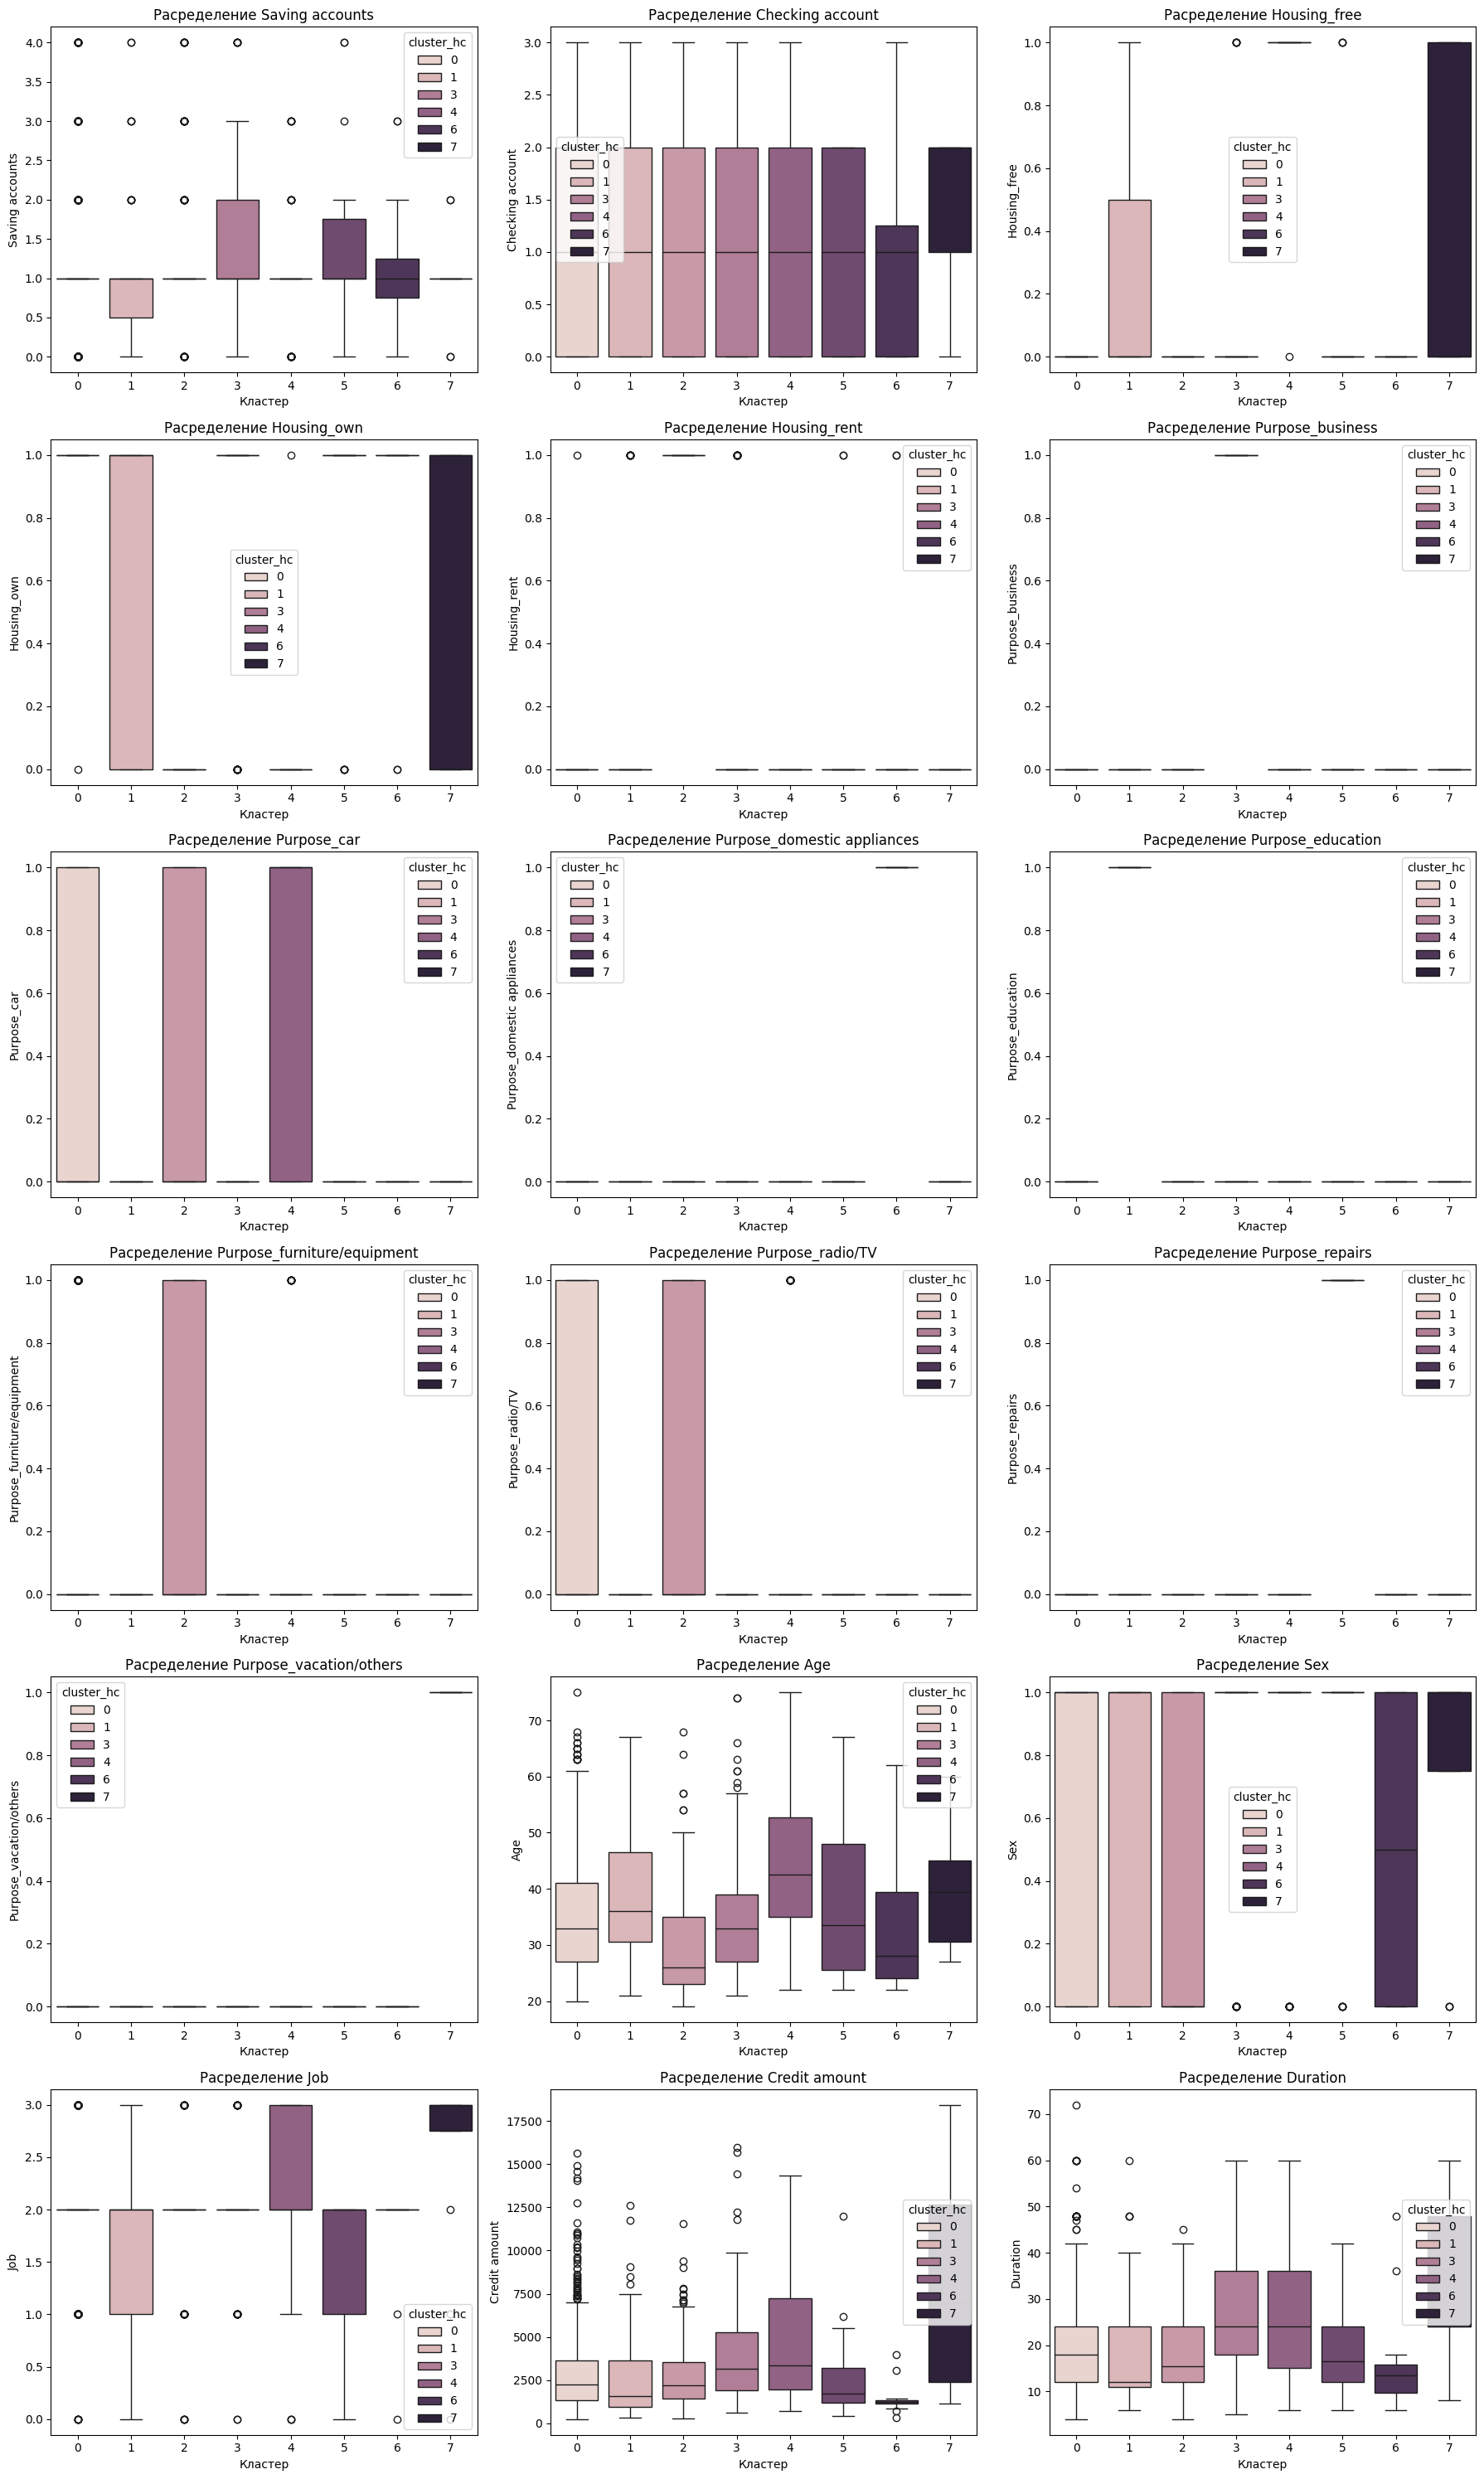

In [170]:
n_cols = 3
n_rows = (len(features) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df_result,
        x="cluster_hc",
        hue="cluster_hc",
        y=feature,
        ax=ax
    )

    ax.set_title(f"Расределение {feature}")
    ax.set_xlabel("Кластер")

plt.tight_layout()
plt.show()

1. Purpose_car: явно выделяются кластеры 0, 2 и 4, в которых автокредиты составляют значительную долю, а в остальных кластерах 0
2. Housing_own и Housing_fre: кластеры 1 и 7 забирают в себя собственников жилья и живущих бесплатно
3. Purpose_business, Purpose_domestic appliances, Purpose_education, Purpose_repairs и Purpose_vacation/others: на всех графиках это плоские черточки на нуле у большинства кластеров. Только на каком-то одном конкретном  класетере эта черточка поднята на единицу (напр. у кластера 3 для Purpose_business). Это показывает, что данные кластеры полностью состоят из людей с этой одной конкретной целью кредита - только на бизнес, только обучение и т.д.
4. Checking account: почти у всех кластеров сами ящики лежат на одном и том же уровне от 0 до 2 с медианой на 1. Это показывает, что состояние счета Checking account почти не окахывает влияние на попадание человека в тот или оной кластер
5. Credit amount и Duration имеют очень схожую тенденцию. Например, кластер 7 (как я писала выше: `Группа людей, которая берет самый большой кредит на самый длиетльный срок относительно других групп, на цели отпуска или других трат`): у Credit amount медиана ящика находится на уровне 7000 по сумме, у Duration медиана на 36 месяцах по сроку

В целом выглядит так, что  наиболее сильная разделяющая кластеры способность у категориальных признаков типа желья Housing_ и целей кредитов Purpose_ и у числовых признаков Credit amount, Duration, Age, так как они показывают наибольший разброс между кластерами. А более слаабое разделение показывают состояния счетов Checking и Saving accounts, работа Job и пол Sex.